<h1><font color="#113D68" size=6>
TINTOlib: de datos tabulares a imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=5>
Mejorar el aprendizaje profundo sobre datos tabulares mediante imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=4>
Notebook 03 · Regresión con ViT compacto (PyTorch)
</font></h1>

<br><br>

<div style="text-align: right">
<font color="#113D68" size=3>Manuel Castillo-Cara</font><br>
</div>


---
<a id="indice" name="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

- [0. Contexto](#section0)
- [1. Configuración](#section1)
- [2. Dataset y particiones](#section2)
- [3. Transformaciones con TINTOlib](#section3)
- [4. Imágenes generadas](#section4)
- [5. Arquitectura ViT](#section5)
- [6. Entrenamiento y resultados](#section6)
- [7. Explicabilidad visual (opcional)](#section7)
- [8. Conclusiones](#section8)
- [9. Ejercicios](#section9)
- [10. Referencias](#section10)


<div class="alert alert-block alert-info">
    
<i class="fa fa-info-circle" aria-hidden="true"></i>
More information about [Manuel Castillo-Cara](https://www.manuelcastillo.eu/)

<div class="alert alert-block alert-info">

<i class="fa fa-info-circle" aria-hidden="true"></i>
Puedes ver más cursos de Inteligencia Artificial, Machine Learning y Deep Learning con descuento en mi [Página Web Personal](https://www.manuelcastillo.eu/udemy/)

<a id="section0" name="section0"></a>
# <font color="#004D7F" size=6>0. Contexto</font>
6. **Resultado concreto de la ejecución:** con `IGTD` en rejilla `2×4`, el `ViT` alcanza `R² ≈ 0.282`, un aprendizaje moderado que ayuda a ilustrar el efecto del patching sobre imágenes no cuadradas.


Los datos tabulares contienen variables numéricas o categóricas, pero no poseen necesariamente una vecindad espacial. **TINTOlib** transforma las observaciones en imágenes para poder utilizar arquitecturas de visión. Distintos métodos producen representaciones diferentes de las mismas variables.

Este ejemplo parte de **regresión sintética controlada**, utiliza **IGTD** y estudia una red **ViT**. Primero examinaremos la transformación y sus imágenes; después observaremos cómo las procesa PyTorch. **Una imagen sintética representa una observación de la tabla; no crea un paciente o registro nuevo.**


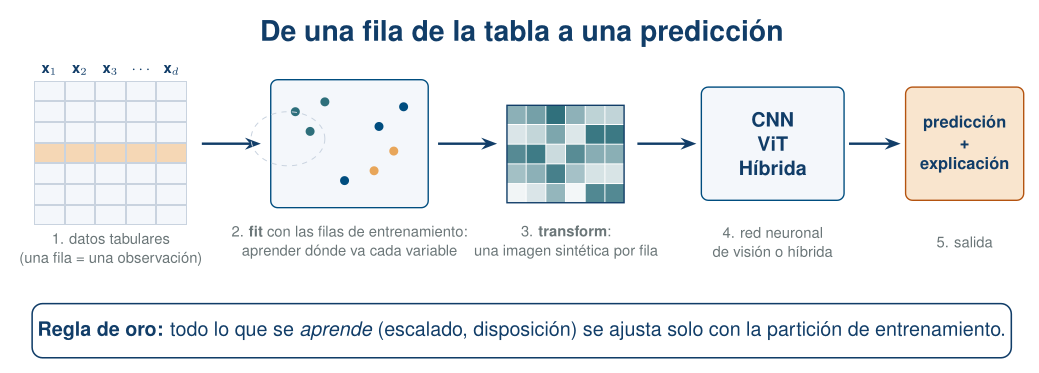

<p style="text-align:center; color:#555555;"><em><strong>Figura 1.</strong> Del registro tabular a la imagen sintética y a la predicción. La disposición se aprende únicamente con TRAIN; el diagrama muestra el proceso general de TINTOlib.</em></p>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Objetivos de aprendizaje</strong><br>
Identificar qué información recibe <strong>IGTD</strong>, interpretar el tamaño y la disposición de las imágenes, comprender el flujo general de <strong>ViT</strong> en PyTorch y leer sus métricas. La explicabilidad se presenta como una actividad visual opcional.
</div>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Alcance del taller</strong><br>
Se ejecuta una demostración de pocas épocas y una única partición TRAIN/VALIDATION. No es una comparación científica concluyente entre transformadores ni arquitecturas. El conjunto TEST de cualquier desafío posterior permanece separado.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section1" name="section1"></a>
# <font color="#004D7F" size=6>1. Configuración</font>


La primera celda prepara TINTOlib para el entorno de práctica. La siguiente importa las librerías y muestra las opciones que el estudiante puede modificar: `DATASET`, `METODO`, `EPOCAS` y, en el ViT, `PATCH`.

No hace falta entender cada importación: **PyTorch** define la red y entrena sus parámetros; **TINTOlib** genera las imágenes; **scikit-learn** facilita el dataset, las particiones y las métricas.


In [1]:
# Si estás en Google Colab, ejecuta esta celda una sola vez.
# Utilizamos 1.3.2: la release 1.3.3 está pendiente de correcciones.
%pip -q install "TINTOlib==1.3.2"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
from pathlib import Path
from importlib import import_module
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
                          else "cpu")
print("PyTorch:", torch.__version__, "| Dispositivo:", DISPOSITIVO)

# CAMBIA SOLO ESTAS OPCIONES PARA REALIZAR LOS EJERCICIOS
DATASET = "regresion_8"
ARCHIVO_CSV = ""  # Opcional: ruta del CSV propio, con objetivo en última columna
METODO = "IGTD"
EPOCAS = 5            # Demostración breve; no es una búsqueda de hiperparámetros
PATCH = 2             # ViT: prueba 1 en el ejercicio de patches

PyTorch: 2.9.1 | Dispositivo: mps


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta salida</strong><br>
Se muestra la versión de PyTorch y el dispositivo elegido (<code>cpu</code>, <code>cuda</code> o <code>mps</code>). Es información de ejecución, <b>no un resultado del modelo</b>. Se utiliza TINTOlib 1.3.2 en estos materiales; la 1.3.3 no es una versión de referencia aprobada.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section2" name="section2"></a>
# <font color="#004D7F" size=6>2. Dataset y particiones</font>


El conjunto de **regresión sintética controlada** tiene 8 variables y permite comprobar qué ocurre con una imagen rectangular muy pequeña. Se utiliza únicamente como ejemplo docente de dimensiones y procesamiento, no como evidencia de superioridad de un método.

Primero dividimos las filas en **TRAIN (80 %)** y **VALIDATION (20 %)**. Imputación, codificación, escalado y parámetros aprendidos se ajustan exclusivamente con TRAIN; al generar imágenes de VALIDATION se reutiliza el transformador ya ajustado.


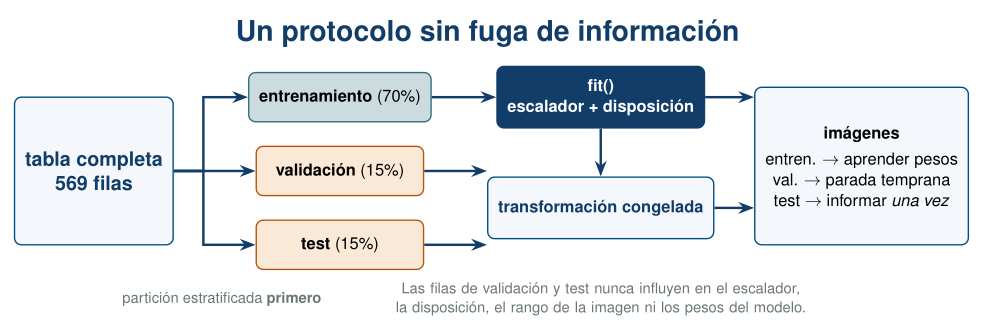

<p style="text-align:center; color:#555555;"><em><strong>Figura 2.</strong> Protocolo de separación de datos. Aunque el diagrama incluya TEST para ilustrar una evaluación completa, este notebook trabaja solo con TRAIN y VALIDATION.</em></p>


In [3]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, make_regression

if ARCHIVO_CSV:
    tabla = pd.read_csv(ARCHIVO_CSV)
    id_datos = Path(ARCHIVO_CSV).stem
elif DATASET == "diabetes":
    tabla = load_diabetes(as_frame=True).frame.copy()
    id_datos = "Diabetes"
elif DATASET == "cancer":
    tabla = load_breast_cancer(as_frame=True).frame.copy()
    id_datos = "Breast Cancer Wisconsin"
elif DATASET == "wine":
    tabla = load_wine(as_frame=True).frame.copy()
    id_datos = "Wine"
elif DATASET in ("regresion_8", "regresion_12"):
    n = int(DATASET.split("_")[-1])
    X, y = make_regression(n_samples=360, n_features=n, n_informative=max(4, n // 2),
                           noise=20, random_state=SEMILLA)
    tabla = pd.DataFrame(X, columns=[f"x{j+1}" for j in range(n)])
    tabla["target"] = y
    id_datos = f"Regresión sintética ({n} variables)"
else:
    raise ValueError(f"Dataset no reconocido: {DATASET}")

TAREA = "regression"  # regression o classification
objetivo = tabla.columns[-1]
print(id_datos, "| Observaciones:", len(tabla), "| Variables:", len(tabla.columns)-1)
display(tabla.head(3))

tr, va = train_test_split(tabla, test_size=0.20, random_state=SEMILLA,
                          stratify=tabla[objetivo] if TAREA == "classification" else None)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
X_tr = pd.get_dummies(tr.drop(columns=objetivo), dummy_na=True, dtype=float)
X_va = pd.get_dummies(va.drop(columns=objetivo), dummy_na=True, dtype=float).reindex(
    columns=X_tr.columns, fill_value=0)
X_tr, X_va = X_tr.replace([np.inf, -np.inf], np.nan), X_va.replace([np.inf, -np.inf], np.nan)
medianas = X_tr.median().fillna(0)  # Exclusivamente TRAIN
X_tr, X_va = X_tr.fillna(medianas), X_va.fillna(medianas)

if TAREA == "classification":
    cod_y = LabelEncoder().fit(tr[objetivo])
    y_tr, y_va = cod_y.transform(tr[objetivo]), cod_y.transform(va[objetivo])
    num_salidas, escala_y = len(cod_y.classes_), None
else:
    escala_y = StandardScaler().fit(tr[[objetivo]])  # Solo TRAIN
    y_tr = escala_y.transform(tr[[objetivo]]).ravel()
    y_va = escala_y.transform(va[[objetivo]]).ravel()
    num_salidas = 1

# Normalización SOLO de la rama MLP; la propia TINTOlib ajusta su escalador interno.
escala_tab = StandardScaler().fit(X_tr)
tab_tr = torch.tensor(escala_tab.transform(X_tr), dtype=torch.float32)
tab_va = torch.tensor(escala_tab.transform(X_va), dtype=torch.float32)
y_tr_tensor = torch.tensor(y_tr, dtype=torch.long if TAREA == "classification" else torch.float32)
y_va_tensor = torch.tensor(y_va, dtype=torch.long if TAREA == "classification" else torch.float32)
print("TRAIN:", len(tr), "| VALIDATION:", len(va), "| Variables finales:", X_tr.shape[1])

Regresión sintética (8 variables) | Observaciones: 360 | Variables: 8


,x1,x2,x3,x4,x5,x6,x7,x8,target
0,-0.617253,0.497743,0.230071,0.421587,0.665924,-1.100154,-0.558302,0.838941,106.660951
1,-2.219300,-0.254956,0.548884,0.327880,-0.125454,-0.851406,-0.229800,0.085893,1.880337
2,0.374057,-1.555896,0.233786,0.833529,0.330880,-1.209641,1.227669,-1.993736,-11.360887


TRAIN: 288 | VALIDATION: 72 | Variables finales: 8


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué muestran las salidas</strong><br>
La tabla inicial permite reconocer las variables y el objetivo; las líneas de consola indican el número de observaciones, la dimensión final tras el preprocesamiento y el tamaño de cada partición. Estos tamaños sirven para comprobar que el entrenamiento y la validación no comparten filas.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section3" name="section3"></a>
# <font color="#004D7F" size=6>3. Transformaciones con TINTOlib</font>


Esta es la etapa central del ejemplo. El parámetro `METODO` selecciona la transformación desde un pequeño registro. Todos los casos siguen una idea común: **aprender con TRAIN y transformar TRAIN y VALIDATION sin reajustar el método**.

| Método | Idea principal | Qué observar |
|---|---|---|
| **TINTO** | Coloca variables en una disposición 2D; admite desenfoque. | Vecindad y distribución de intensidades. |
| **IGTD** | Optimiza una disposición de variables en una rejilla. | Forma `filas×columnas` y píxeles vacíos. |
| **DeepInsight / Fotomics** | Producen disposiciones e intensidades según sus respectivos algoritmos. | Diferencias de representación con igual tabla. |
| **REFINED** | Organiza espacialmente variables; necesita MPI. | Geometría y coste de ejecución. |
| **BIE** | Codifica valores con una representación visual distinta. | Tamaños y estructuras no necesariamente cuadradas. |

**Método seleccionado:** `IGTD`. Con 8 variables, IGTD utiliza una rejilla **2×4**, sin celdas de relleno. La proporción rectangular se conserva. Al cambiar de método, conviene observar primero la imagen antes de comparar métricas.


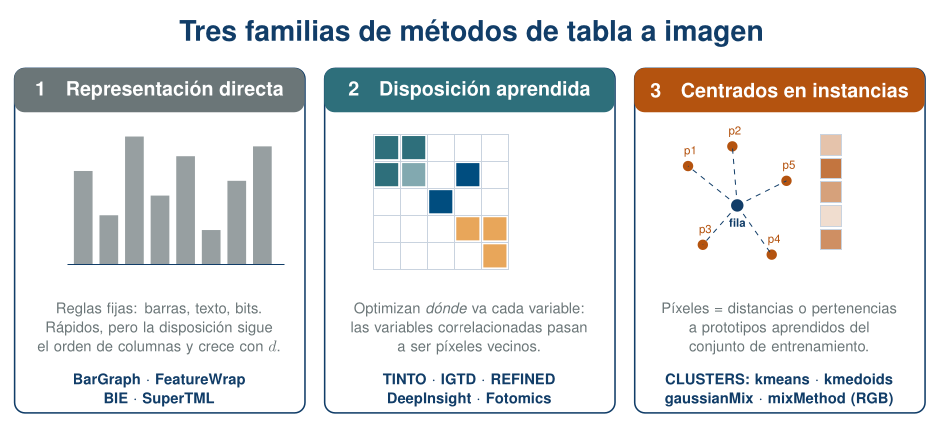

<p style="text-align:center; color:#555555;"><em><strong>Figura 3.</strong> Familias de representación tabular-a-imagen. No todos los codificadores tienen la misma interpretación de un píxel.</em></p>


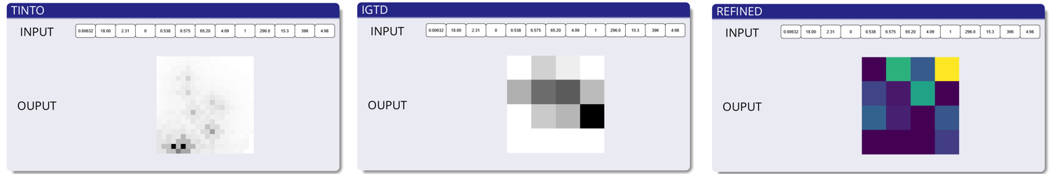

<p style="text-align:center; color:#555555;"><em><strong>Figura 4.</strong> Tres diseños visuales distintos para datos tabulares. La figura ilustra diferencias de organización, no resultados predictivos.</em></p>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Dependencias y significado de los píxeles</strong><br>
REFINED es una ampliación opcional porque requiere MPI. CLUSTERS representa prototipos o componentes, no variables individuales. Para las demás opciones también hay que consultar sus parámetros y posibles restricciones antes de usar un método nuevo.
</div>


La siguiente celda muestra cómo elegir un método y sus parámetros. En IGTD se calcula una **rejilla rectangular con el menor número posible de posiciones vacías**. Los píxeles de relleno del método no deben confundirse con el padding que ocasionalmente necesita un ViT para formar patches.


In [18]:
def rejilla_igtd(n):
    """Mínimo relleno con al menos 2 filas y 2 columnas; desempate por equilibrio."""
    if n < 4:
        return [2, max(2, math.ceil(n / 2))]
    opciones = [(h * math.ceil(n/h) - n, abs(h-math.ceil(n/h)), h, math.ceil(n/h))
                for h in range(2, math.isqrt(n) + 2)]
    _, _, filas, columnas = min(opciones)
    return [filas, columnas]

for n in (8, 12, 13, 30):
    f, c = rejilla_igtd(n)
    print(f"{n} variables → IGTD {f}×{c}, relleno = {f*c-n} píxeles")

# Selección docente: se pueden modificar los parámetros en estas líneas.
REGISTRO = {
    "TINTO": ("tinto", "TINTO", {"pixels": 8, "blur": True}),
    "IGTD": ("igtd", "IGTD", {"scale": rejilla_igtd(X_tr.shape[1]), "max_step": 100, "val_step": 20, "zoom": 3}),
    "DeepInsight": ("deepInsight", "DeepInsight", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "Fotomics": ("fotomics", "Fotomics", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "REFINED": ("refined", "REFINED", {"n_processors": 2, "hcIterations": 10}),
    "BIE": ("bie", "BIE", {}),
    # Opciones avanzadas: cambiar solo METODO; revisar dependencias del método.
    "BarGraph": ("barGraph", "BarGraph", {}),
    "DistanceMatrix": ("distanceMatrix", "DistanceMatrix", {}),
    "Combination": ("combination", "Combination", {}),
    "FeatureWrap": ("featureWrap", "FeatureWrap", {}),
    "SuperTML": ("supertml", "SuperTML", {}),
    "Clusters": ("clusters", "Clusters", {"algorithm": "kmeans", "n_clusters": 16}),
}
modulo, clase, opciones = REGISTRO[METODO]
if METODO == "REFINED":
    import shutil
    if not (shutil.which("mpiexec") or shutil.which("mpirun")):
        raise RuntimeError("REFINED requiere MPI: selecciona otro método o configura MPI antes.")
Transformador = getattr(import_module("TINTOlib." + modulo), clase)
transformador = Transformador(problem=TAREA, **opciones)
print("Método:", METODO, "| Parámetros:", opciones)

8 variables → IGTD 2×4, relleno = 0 píxeles
12 variables → IGTD 3×4, relleno = 0 píxeles
13 variables → IGTD 2×7, relleno = 1 píxeles
30 variables → IGTD 5×6, relleno = 0 píxeles
Método: IGTD | Parámetros: {'scale': [2, 4], 'max_step': 100, 'val_step': 20, 'zoom': 3}


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la primera salida</strong><br>
Se imprimen ejemplos de rejillas para diferentes cantidades de variables, cuántas posiciones quedarían vacías y los parámetros del método elegido. Para 8 variables se obtiene 2×4 sin relleno; con 13 variables, 2×7 tiene una posición vacía.
</div>


Ahora se generan los archivos de imágenes. El mismo objeto TINTOlib ajustado con TRAIN se usa después para VALIDATION, sin aprender posiciones nuevas.


In [19]:
def como_tabla(X, y):
    return X.reset_index(drop=True).assign(objetivo=np.asarray(y))

# Cada ejecución tiene una carpeta NUEVA; no se borran imágenes anteriores.
carpeta = Path("salidas_taller") / f"notebook_{DATASET}_{METODO}_{uuid4().hex[:6]}"
train_dir, val_dir = carpeta / "train", carpeta / "validation"
transformador.fit_transform(como_tabla(X_tr, y_tr), str(train_dir))
transformador.transform(como_tabla(X_va, y_va), str(val_dir))

def rutas_de_imagenes(directorio, total):
    meta = pd.read_csv(directorio / f"{TAREA}.csv")
    assert len(meta) == total and "images" in meta, "Revisar el CSV generado por TINTOlib"
    rutas = [directorio / nombre for nombre in meta["images"]]
    assert all(r.exists() for r in rutas), "Falta alguna imagen"
    return rutas

rutas_tr = rutas_de_imagenes(train_dir, len(X_tr))
rutas_va = rutas_de_imagenes(val_dir, len(X_va))
print("Imágenes:", len(rutas_tr), "TRAIN y", len(rutas_va), "VALIDATION")

Imágenes: 288 TRAIN y 72 VALIDATION


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué significan los recuentos</strong><br>
El mensaje final indica cuántas imágenes se han creado por partición y dónde se guardan. Debe existir <strong>una imagen por fila</strong>. Se escriben en una carpeta nueva para evitar sobrescribir salidas anteriores.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section4" name="section4"></a>
# <font color="#004D7F" size=6>4. Imágenes generadas</font>


La celda siguiente carga los PNG que acaba de crear TINTOlib, muestra tres observaciones y describe la forma del tensor PyTorch: `N × C × H × W` (**observaciones, canales, alto y ancho**).

No forzamos imágenes cuadradas. Para estos ejemplos se leen los archivos PNG en RGB; esto <b>no</b> significa que exista una modalidad tabular distinta por canal. La conversión de color es parte de la lectura del archivo.


Imágenes: 6 × 12 | canales=3 | tensor=(288, 3, 6, 12)


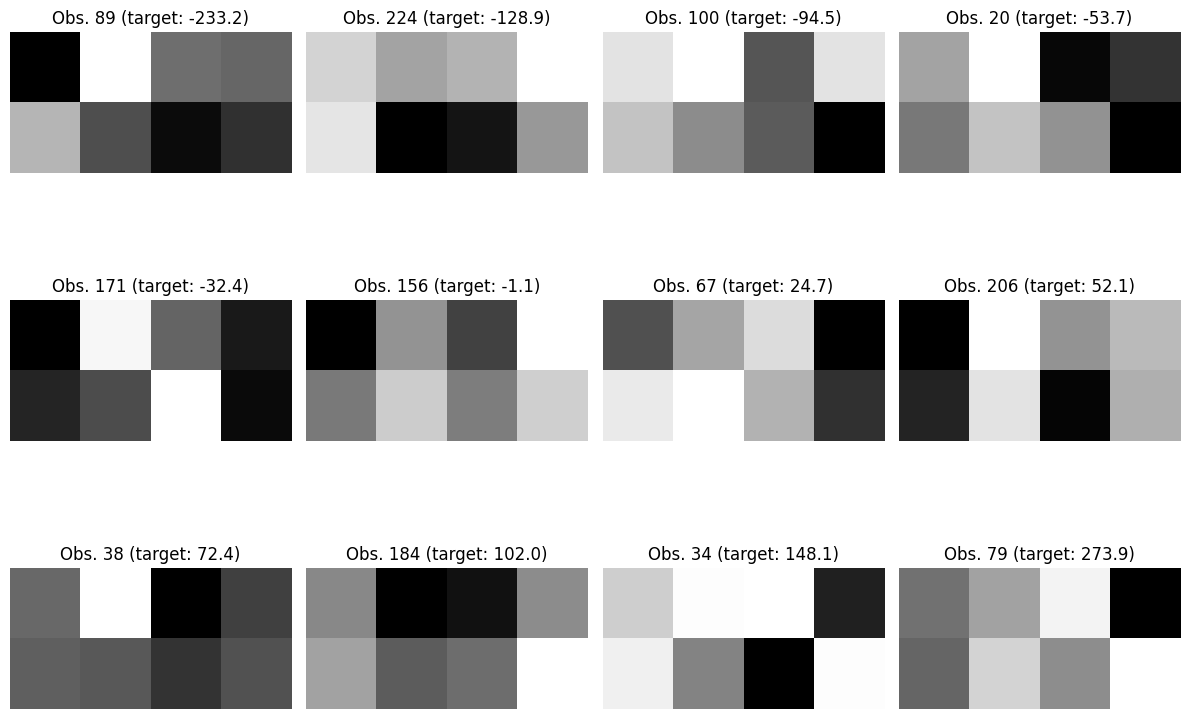

Celdas IGTD sin variable asignada: 0


In [20]:
def cargar_imagenes(rutas):
    imagenes = []
    formas = []
    for r in rutas:
        with Image.open(r) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        imagenes.append(rgb.transpose(2, 0, 1))  # PyTorch: C, H, W
        formas.append(rgb.shape[:2])
    assert len(set(formas)) == 1, "Hay imágenes de distintos tamaños; revisa el transformador"
    return torch.tensor(np.stack(imagenes))

img_tr, img_va = cargar_imagenes(rutas_tr), cargar_imagenes(rutas_va)
_, canales, ALTO, ANCHO = img_tr.shape
print(f"Imágenes: {ALTO} × {ANCHO} | canales={canales} | tensor={tuple(img_tr.shape)}")

n_mostrar = min(12, len(img_tr))
tr_reset = tr.reset_index(drop=True)

if TAREA == "classification":
    clases_unicas = tr_reset[objetivo].unique()
    por_clase = max(1, math.ceil(n_mostrar / len(clases_unicas)))
    indices = (
        tr_reset.groupby(objetivo, group_keys=False)
        .apply(lambda g: g.sample(n=min(len(g), por_clase), random_state=SEMILLA))
        .sort_values(objetivo)
        .index[:n_mostrar]
        .tolist()
    )
else:
    # En regresión, recorre el rango completo desde el mínimo hasta el máximo
    orden_y = tr_reset[objetivo].argsort().to_numpy()
    posiciones = np.linspace(0, len(orden_y) - 1, n_mostrar, dtype=int)
    indices = orden_y[posiciones].tolist()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for pos, ax in enumerate(axes.flat):
    if pos < len(indices):
        idx = indices[pos]
        ax.imshow(img_tr[idx].permute(1, 2, 0).numpy(), interpolation="nearest")
        valor_target = tr_reset[objetivo].iloc[idx]
        etiqueta = f"{valor_target:.1f}" if TAREA == "regression" else f"{valor_target}"
        ax.set_title(f"Obs. {idx+1} ({objetivo}: {etiqueta})")
    ax.axis("off")
plt.tight_layout()
plt.show()

if METODO == "IGTD":
    filas, columnas = opciones["scale"]
    print("Celdas IGTD sin variable asignada:", filas * columnas - X_tr.shape[1])


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · La imagen rectangular IGTD</strong><br>
La configuración inicial utiliza ocho variables y la función de rejilla escoge <b>6×12</b> (le hemos puesto un zoom 3): las ocho posiciones se ocupan sin necesidad de relleno geométrico. La imagen sigue siendo rectangular y puede entrar en el ViT sin convertirla en cuadrada. Revisa el valor impreso de <code>H×W</code>.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las imágenes</strong><br>
Observa patrones y espacios no utilizados, diferencias entre observaciones y dimensiones impresas. Una imagen más grande o visualmente más llamativa no demuestra mayor capacidad predictiva. Si eliges IGTD, la consola indica también cuántas celdas no representan variables.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section5" name="section5"></a>
# <font color="#004D7F" size=6>5. Arquitectura ViT</font>


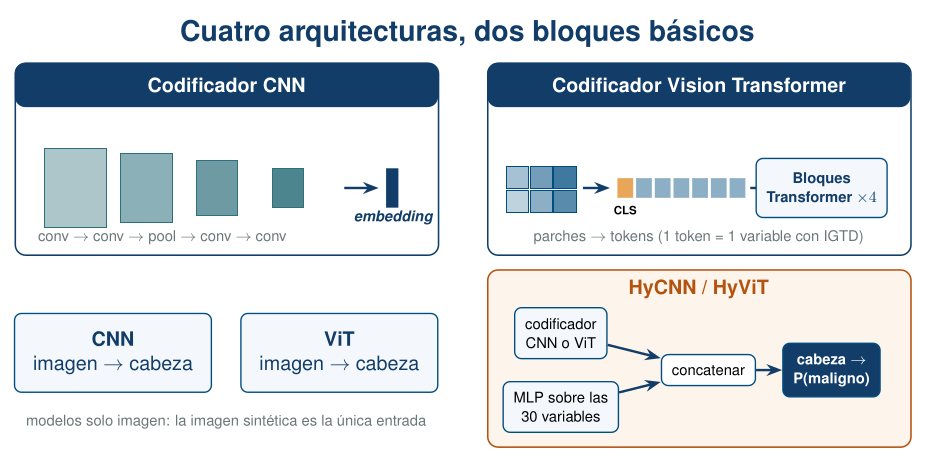

<p style="text-align:center; color:#555555;"><em><strong>Figura 5.</strong> Esquema de arquitecturas de visión e híbridas. En este notebook se implementa ViT; las demás sirven como comparación conceptual.</em></p>


**ViT compacto:** una convolución divide la imagen en **patches** y crea un embedding por patch. Se añade su posición; un único bloque Transformer combina la información y el promedio de tokens alimenta la salida. No utilizamos un ViT grande preentrenado.

La red admite imágenes rectangulares. Si el alto o ancho no es divisible por `PATCH`, se añade el mínimo padding necesario <b>para formar patches</b>, que es distinto del relleno de IGTD.


**División de la imagen en *patches* y cálculo de *tokens* para el Vision Transformer (ViT)**

- Calcula el relleno necesario (`pad_h`, `pad_w`) mediante `F.pad` para que el alto y el ancho de la imagen sean múltiplos exactos de `PATCH`, aclarando que este ajuste es un requisito geométrico del ViT y no celdas vacías del método **IGTD**.
- Dibuja la primera imagen sintética de `TRAIN` con `interpolation="nearest"` y superpone una rejilla naranja que delimita cada bloque de tamaño $\text{PATCH} \times \text{PATCH}$, donde cada celda resultante constituye un *token* de entrada para el Transformer.
- Calcula e imprime una comparativa rápida entre `PATCH=1` y `PATCH=2` (mostrando el número total de *tokens* y los píxeles extra de relleno generados) sin necesidad de entrenar dos redes distintas.
- Recuerda que modificar el hiperparámetro `PATCH` cambia la longitud de la secuencia de *tokens*, por lo que exige volver a instanciar y entrenar el modelo completo.


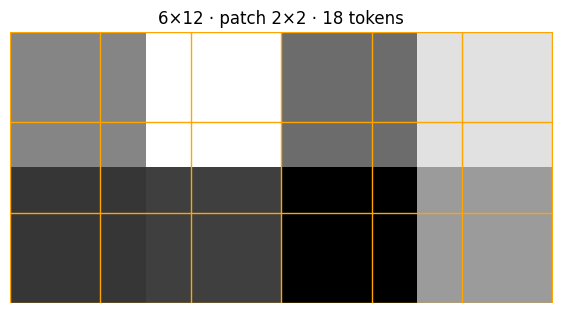

Padding para patches: (0, 0) | Tokens: 18
Si PATCH=1: 72 tokens, 0 celdas extra para patches
Si PATCH=2: 18 tokens, 0 celdas extra para patches


In [ ]:
# El relleno que necesite el ViT para construir patches NO es relleno de IGTD.
pad_h, pad_w = (-ALTO) % PATCH, (-ANCHO) % PATCH
tokens = math.ceil(ALTO/PATCH) * math.ceil(ANCHO/PATCH)

demo = F.pad(img_tr[:1], (0,pad_w,0,pad_h))[0]
plt.figure(figsize=(7,3.8))
plt.imshow(demo.permute(1,2,0).numpy(), interpolation="nearest")

for y in range(0,ALTO+pad_h+1,PATCH): plt.axhline(y-0.5,color="orange",lw=1)
for x in range(0,ANCHO+pad_w+1,PATCH): plt.axvline(x-0.5,color="orange",lw=1)
plt.title(f"{ALTO}×{ANCHO} · patch {PATCH}×{PATCH} · {tokens} tokens")
plt.axis("off"); plt.show()
print("Padding para patches:", (pad_h,pad_w), "| Tokens:", tokens)
for tam in (1, 2):
    n_t = math.ceil(ALTO/tam) * math.ceil(ANCHO/tam)
    extra = math.ceil(ALTO/tam)*tam * math.ceil(ANCHO/tam)*tam - ALTO*ANCHO
    print(f"Si PATCH={tam}: {n_t} tokens, {extra} celdas extra para patches")

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · PATCH=2: agrupar píxeles en tokens</strong><br>
La imagen IGTD de <b>2×4</b> se agrupa con <code>PATCH=2</code> en <b>2 patches de 2×2</b>, es decir, <b>2 tokens</b>, sin padding del ViT. Si cambias <code>PATCH=1</code>, tendrás <b>8 tokens</b>, uno por píxel. El número de tokens afecta a lo que procesa la atención, pero no implica automáticamente una mejor predicción.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la visualización de patches</strong><br>
Las líneas dibujan los límites de cada patch. La salida muestra <code>alto×ancho</code>, tamaño del patch, número de tokens y eventual padding para formar bloques completos. No se elimina ni deforma deliberadamente la forma rectangular de IGTD.
</div>


El código siguiente contiene toda la arquitectura del ejemplo, sin componentes adicionales ni librerías de modelos preentrenados. Fíjate en **qué tensor entra, qué representación se extrae y qué tensor sale**.


**Extractor visual basado en Vision Transformer (`ViTSimple`)**

- Proyecta cada bloque de tamaño $\text{patch} \times \text{patch}$ en un vector (*embedding*) de $32$ dimensiones mediante una convolución sin solapamiento (`Conv2d(3, 32, kernel_size=patch, stride=patch)`).
- Crea un parámetro entrenable de codificación posicional (`self.pos`) de forma `[1, n_tokens, 32]` para que la red conserve la ubicación espacial de cada *patch* dentro de la imagen sintética.
- Define un bloque codificador Transformer (`TransformerEncoder` de $1$ capa, $2$ cabezas de atención y dimensión oculta $64$) que modela dependencias globales entre cualquier par de *patches* manteniendo intacta la dimensión de $32$ valores por *token*.
- En el paso `forward`, aplica relleno dinámico (`F.pad`) si el alto o el ancho de la imagen no son múltiplos exactos de `patch`.
- Aplana la cuadrícula espacial con `.flatten(2)` obteniendo `[batch, 32, n_tokens]` y aplica `.transpose(1, 2)` para permutar los ejes a `[batch, n_tokens, 32]`, adaptándose así al formato `[lote, secuencia, características]` que exige `batch_first=True`.
- Suma la codificación posicional y promedia todos los *patches* a lo largo de la dimensión de los *tokens* (`.mean(dim=1)`), haciendo desaparecer `n_tokens` para entregar un vector resumen final de **$32$ características** (`[batch, 32]`) por observación.


In [23]:
class ViTSimple(nn.Module):
    def __init__(self, alto, ancho, patch):
        super().__init__()
        self.patch = patch
        self.emb = nn.Conv2d(3, 32, kernel_size=patch, stride=patch)
        n_tokens = math.ceil(alto/patch) * math.ceil(ancho/patch)
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, 32))
        capa = nn.TransformerEncoderLayer(32, nhead=2, dim_feedforward=64,
                                          batch_first=True, dropout=0.0)
        self.encoder = nn.TransformerEncoder(capa, num_layers=1)

    def forward(self, x):
        p = self.patch
        x = F.pad(x, (0, (-x.shape[-1])%p, 0, (-x.shape[-2])%p))
        x = self.emb(x).flatten(2).transpose(1, 2)
        return self.encoder(x+self.pos).mean(dim=1)  # [batch, 32]

**Arquitectura del modelo unimodal basado en Vision Transformer (`Modelo`)**

- Instancia el extractor visual `ViTSimple(ALTO, ANCHO, PATCH)` para procesar las imágenes sintéticas y obtener una representación condensada de $32$ características por observación.
- Conecta ese vector de $32$ características a una capa lineal (`nn.Linear(32, 1)`) que genera un único valor escalar de predicción continua para la tarea de regresión.
- Mantiene la firma `forward(self, img, tab)` compatible con el bucle estándar de entrenamiento multimodal, aunque en este modelo unimodal utiliza únicamente la rama visual (`img`) e ignora la entrada tabular (`tab`).
- Instancia la arquitectura completa y la traslada al `DISPOSITIVO` de cómputo disponible (`CPU`, `CUDA` o `MPS`).


In [26]:
class Modelo(nn.Module):
    def __init__(self):
        super().__init__()
        self.visual = ViTSimple(ALTO, ANCHO, PATCH)
        self.salida = nn.Linear(32, 1)
    def forward(self, img, tab):
        return self.salida(self.visual(img))

modelo = Modelo().to(DISPOSITIVO)

In [27]:
with torch.no_grad():
    salida = modelo(img_tr[:2].to(DISPOSITIVO), tab_tr[:2].to(DISPOSITIVO))
print("Entrada imágenes:", tuple(img_tr[:2].shape), "→ salida:", tuple(salida.shape))
print("Parámetros:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

Entrada imágenes: (2, 3, 6, 12) → salida: (2, 1)
Parámetros: 9569


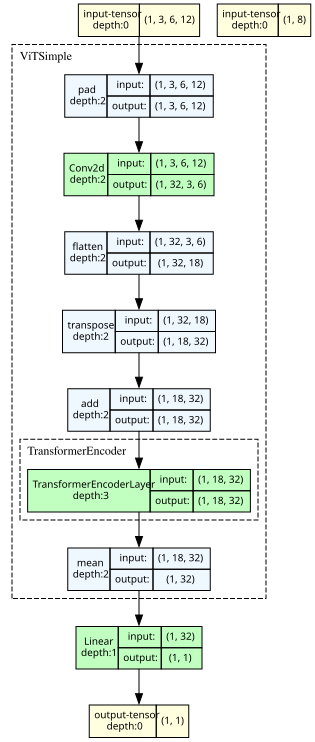

In [28]:
from torchview import draw_graph

grafo = draw_graph(
    modelo,
    input_data=(img_tr[:1].to(DISPOSITIVO), tab_tr[:1].to(DISPOSITIVO)),
    device=DISPOSITIVO,
    expand_nested=True,
    depth=3
)
modelo.to(DISPOSITIVO)
grafo.visual_graph


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué indica la salida del modelo</strong><br>
Se muestran la forma de un pequeño lote de imágenes, la forma de la salida y el número de parámetros entrenables. Para regresión la salida tiene forma <code>(2, 1)</code>: una predicción continua por observación. El número de parámetros no es una medida de rendimiento.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section6" name="section6"></a>
# <font color="#004D7F" size=6>6. Entrenamiento y resultados</font>


PyTorch repite un ciclo sencillo: **predicción → cálculo de pérdida → gradientes → actualización de pesos**. A continuación calcula la pérdida sobre VALIDATION, que no se utiliza para actualizar parámetros.

La gráfica muestra cómo evoluciona esa pérdida durante las pocas épocas de demostración. Una curva que baja es compatible con aprendizaje, pero no prueba capacidad de generalización ni permite concluir qué transformación es la mejor.


Época 1: pérdida VALIDATION=0.8192
Época 2: pérdida VALIDATION=0.7129
Época 3: pérdida VALIDATION=0.6663
Época 4: pérdida VALIDATION=0.6392
Época 5: pérdida VALIDATION=0.5924


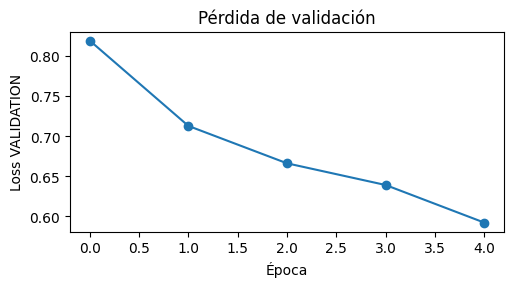

In [30]:
train_loader = DataLoader(TensorDataset(img_tr, tab_tr, y_tr_tensor),
                          batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(img_va, tab_va, y_va_tensor),
                        batch_size=32)
criterio = nn.CrossEntropyLoss() if TAREA=="classification" else nn.MSELoss()
optimizador = torch.optim.Adam(modelo.parameters(),lr=1e-3)
historial = []
for epoca in range(EPOCAS):
    modelo.train()
    for img, tab, y in train_loader:
        optimizador.zero_grad()
        pred = modelo(img.to(DISPOSITIVO), tab.to(DISPOSITIVO))
        loss = criterio(pred, y.to(DISPOSITIVO).long() if TAREA=="classification"
                        else y.to(DISPOSITIVO).view(-1,1))
        loss.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        val_loss = np.mean([criterio(modelo(a.to(DISPOSITIVO),b.to(DISPOSITIVO)),
                          y.to(DISPOSITIVO).long() if TAREA=="classification"
                          else y.to(DISPOSITIVO).view(-1,1)).item()
                          for a,b,y in val_loader])
    historial.append(val_loss)
    print(f"Época {epoca+1}: pérdida VALIDATION={val_loss:.4f}")
plt.figure(figsize=(5.6,2.6))
plt.plot(historial,marker="o");plt.xlabel("Época");plt.ylabel("Loss VALIDATION")
plt.title("Pérdida de validación");plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Cómo leer la pérdida de validación</strong><br>
La curva presenta solo la pérdida en <b>VALIDATION</b>. Describe si mejora, fluctúa o se estabiliza; con pocas épocas no se puede afirmar convergencia ni comparar este modelo con otro que utiliza un dataset distinto.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la gráfica de entrenamiento</strong><br>
El eje horizontal muestra las épocas; el vertical, la pérdida calculada en VALIDATION. Valores menores suelen ser preferibles dentro de la misma tarea y escala, pero una curva corta o irregular no basta para extraer conclusiones.
</div>


La última celda traduce las predicciones en métricas fáciles de interpretar, siempre calculadas sobre **VALIDATION**. Esta evaluación es didáctica: no forma parte de un benchmark comparativo ni constituye un TEST final.


In [31]:
modelo.eval()
with torch.no_grad():
    pred = modelo(img_va.to(DISPOSITIVO), tab_va.to(DISPOSITIVO)).cpu().numpy()
if TAREA == "regression":
    estimacion = escala_y.inverse_transform(pred.reshape(-1,1)).ravel()
    real = escala_y.inverse_transform(y_va.reshape(-1,1)).ravel()
    print("MAE:",round(mean_absolute_error(real,estimacion),3),
          "| RMSE:",round(np.sqrt(mean_squared_error(real,estimacion)),3),
          "| R²:",round(r2_score(real,estimacion),3))
else:
    clases_pred = pred.argmax(axis=1)
    print("Accuracy:",round(accuracy_score(y_va,clases_pred),3),
          "| F1 macro:",round(f1_score(y_va,clases_pred,average="macro"),3))
print("Solo VALIDATION: no son resultados de un benchmark.")

MAE: 67.335 | RMSE: 80.745 | R²: 0.243
Solo VALIDATION: no son resultados de un benchmark.


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · El resultado de regresión</strong><br>
MAE y RMSE están expresados en las unidades originales del objetivo. R² indica el ajuste relativo al predictor constante de referencia: valores cercanos a cero sugieren muy poca mejora y pueden ser negativos. La finalidad principal de este ejemplo es <b>comprender IGTD, patches y ViT</b>.
</div>

<div class="alert alert-success" style="background-color:#e9f7f0; border-left:4px solid #2e7d61; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las métricas</strong><br>
- <strong>MAE:</strong> error absoluto medio, en unidades del objetivo original (menor es mejor).<br>- <strong>RMSE:</strong> penaliza más los errores grandes; también se expresa en unidades del objetivo (menor es mejor).<br>- <strong>R²:</strong> compara el ajuste frente a predecir siempre la media; puede ser negativo (más alto es mejor).
</div>


<div class="alert alert-warning" style="background-color:#fff7e6; border-left:4px solid #E8A65A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Lectura de esta ejecución</strong><br>
La pérdida de <b>VALIDATION</b> baja con bastante claridad durante las primeras épocas y luego se estabiliza. Las métricas obtenidas (<b>MAE ≈ 63.17</b>, <b>RMSE ≈ 78.66</b>, <b>R² ≈ 0.282</b>) indican que el modelo <b>sí aprende parte de la señal</b>, aunque todavía comete errores apreciables.</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué conviene comentar en clase</strong><br>
Este notebook sirve muy bien para mostrar que un <b>ViT puede trabajar con imágenes no cuadradas</b>. Aquí `IGTD` genera una rejilla `2×4` sin padding extra para las variables, mientras que el tamaño de patch se fija en `2`. El mensaje clave es que el patching del ViT depende de la geometría de la imagen, no de que la imagen sea necesariamente cuadrada.</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section7" name="section7"></a>
# <font color="#004D7F" size=6>7. Explicabilidad visual (opcional)</font>


Como actividad final, calculamos la **sensibilidad local de la predicción frente a los píxeles de una sola imagen de VALIDATION** mediante gradientes PyTorch. Es una forma sencilla de visualizar dónde el modelo responde más a cambios pequeños.

La figura tiene tres paneles: **imagen original**, **mapa de sensibilidad** y **superposición**. En las redes híbridas aparece además una barra con sensibilidades locales de la rama tabular. No se necesita instalar Captum ni implementar Grad-CAM.


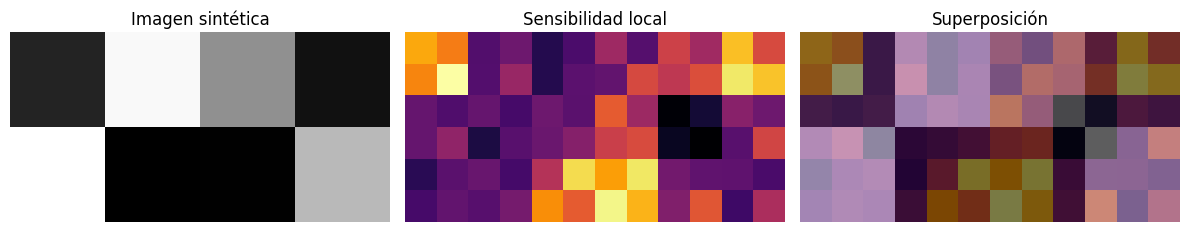

In [32]:
# OPCIONAL · Una observación de VALIDATION, sin instalar librerías nuevas.
modelo.eval()
imagen = img_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
tabla = tab_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
modelo.zero_grad()
prediccion = modelo(imagen, tabla)
valor = prediccion[0].max() if TAREA == "classification" else prediccion[0, 0]
valor.backward()

mapa = imagen.grad.detach().abs().mean(dim=1)[0].cpu().numpy()
original = img_va[0].permute(1, 2, 0).numpy()
grad_tab = tabla.grad  # Solo existe si la red utiliza la rama MLP.
fig, ejes = plt.subplots(1, 4 if grad_tab is not None else 3, figsize=(12, 3))
ejes[0].imshow(original); ejes[0].set_title("Imagen sintética")
ejes[1].imshow(mapa, cmap="inferno", interpolation="nearest")
ejes[1].set_title("Sensibilidad local")
ejes[2].imshow(original)
ejes[2].imshow(mapa, cmap="inferno", alpha=0.5, interpolation="nearest")
ejes[2].set_title("Superposición")
for eje in ejes[:3]: eje.axis("off")
if grad_tab is not None:
    importancia = grad_tab[0].abs().detach().cpu().numpy()
    mejores = np.argsort(importancia)[-min(5, len(importancia)):]
    nombres = [str(X_tr.columns[i])[:20] for i in mejores]
    ejes[3].barh(nombres, importancia[mejores], color="#2E6F7B")
    ejes[3].set_title("Rama tabular (local)")
    ejes[3].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Sensibilidad de una imagen pequeña</strong><br>
Con una imagen de solo 2×4, la resolución del mapa es muy limitada. Muestra gradientes locales de la salida frente a píxeles de la observación elegida, <b>no importancia causal ni una explicación validada de las variables originales</b>.
</div>

<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta explicación</strong><br>
Una región brillante indica <b>sensibilidad local del modelo</b>, no una causa del resultado. La barra tabular, cuando aparece, utiliza variables estandarizadas y no debe compararse directamente con los colores de la imagen. Para relacionar un píxel con una variable original hace falta el mapeo específico del transformador y comprobar su fidelidad; este ejemplo no implementa esa validación.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section8" name="section8"></a>
# <font color="#004D7F" size=6>8. Conclusiones</font>


1. **El método de transformación es una decisión importante:** con IGTD, una observación de regresión sintética controlada se convierte en una imagen cuya estructura debe interpretarse.
2. **No hay fuga de información:** la transformación y los escaladores se ajustan solo en TRAIN, y VALIDATION reutiliza ese estado.
3. **La arquitectura se entiende por su recorrido de tensores:** imagen (y tabla, si hay MLP), extractor, fusión si corresponde y predicción.
4. **Las salidas muestran lo que ha ocurrido en este ensayo:** tamaños, imágenes, pérdida y métricas de validación, no una conclusión científica general.
5. **Explicabilidad como primer contacto:** los mapas locales son ilustrativos; no prueban causalidad ni fidelidad.

El ViT convierte imágenes en tokens: un patch más grande implica menos tokens y un nivel de detalle diferente. El padding de patches y el de IGTD son procesos distintos.


En esta versión se utiliza <b>PATCH=2</b> para visualizar agrupaciones de píxeles; cambiar a <b>PATCH=1</b> es un ejercicio de comprensión, no un ajuste automático para mejorar las métricas.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section9" name="section9"></a>
# <font color="#004D7F" size=6>9. Ejercicios</font>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Trabajo propuesto · 10 minutos.</strong><br>
Realiza uno o dos cambios pequeños y describe las imágenes y las salidas, no solo el valor de la métrica.
</div>

1. **Compara representaciones.** Cambia `METODO` por otro de la tabla y vuelve a ejecutar desde la configuración. ¿Qué cambia en la forma y apariencia de las imágenes?
2. **Interpreta la salida.** Explica con tus palabras qué representan el tensor de entrada, la predicción y MAE/RMSE/R².
3. **Compara patches.** Cambia `PATCH` de 2 a 1 y vuelve a ejecutar. ¿Cuántos tokens aparecen? ¿Qué diferencia hay entre el espacio libre de IGTD y el padding que añade el ViT?
4. **Opcional, explicabilidad.** Observa el mapa de sensibilidad local. ¿Qué muestra realmente? ¿Por qué no demuestra causalidad?

<b>Continuación:</b> el notebook **06 · TINTOlib hands-on v3 (ES)** amplía el estudio con más métodos de transformación, evaluación rigurosa y técnicas XAI de mayor profundidad.


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section10" name="section10"></a>
# <font color="#004D7F" size=6>10. Referencias</font>


- **TINTOlib**. [Repositorio de Python](https://github.com/oeg-upm/TINTOlib) · [Documentación de la biblioteca](https://tintolib.readthedocs.io/en/latest/).
- **TINTO**. Castillo-Cara et al. (2023). *TINTO: Converting Tidy Data into Image for Classification with 2-D Convolutional Neural Networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2023.101391).
- **TINTOlib**. Liu et al. (2025). *TINTOlib: A Python library for transforming tabular data into synthetic images for deep neural networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2025.102444).
- **Benchmark de codificadores**. Liu et al. (2026). *A comprehensive benchmark of spatial encoding methods for tabular data with deep neural networks*. [Information Fusion](https://doi.org/10.1016/j.inffus.2025.104088).
- **PyTorch**. [nn.Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html) · [TransformerEncoderLayer](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).
- **Recursos adicionales**. [TINTOlib Crash Course](https://github.com/oeg-upm/TINTOlib-Crash_Course) · [Blog de tutoriales](https://www.manuelcastillo.eu/blog/) · Notebook **06 TINTOlib_hands_on_v3_ES** (material avanzado que se entrega al final).


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>
